In [7]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV, GridSearchCV, KFold
from sklearn.linear_model import LogisticRegression, LinearRegression, SGDRegressor
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, BaggingClassifier, RandomForestRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import LinearSVC, SVR
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.metrics import ConfusionMatrixDisplay, f1_score, make_scorer, confusion_matrix, mean_squared_error, mean_absolute_error

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

from xgboost import XGBClassifier, XGBRegressor
from catboost import CatBoostClassifier

from scipy.stats import randint, uniform



In [8]:
### 1.Basic Cleaning and creating Train/Test Split
### 1.1 reading the data and inspection


In [9]:
raw_data = pd.read_csv('data/car_insurance_claim.csv')

In [10]:

pd.set_option('display.max_columns', None)

raw_data.head()

,ID,KIDSDRIV,BIRTH,AGE,HOMEKIDS,YOJ,INCOME,PARENT1,HOME_VAL,MSTATUS,GENDER,EDUCATION,OCCUPATION,TRAVTIME,CAR_USE,BLUEBOOK,TIF,CAR_TYPE,RED_CAR,OLDCLAIM,CLM_FREQ,REVOKED,MVR_PTS,CLM_AMT,CAR_AGE,CLAIM_FLAG,URBANICITY
0,63581743,0,16MAR39,60.0,0,11.0,"$67,349",No,$0,z_No,M,PhD,Professional,14,Private,"$14,230",11,Minivan,yes,"$4,461",2,No,3,$0,18.0,0,Highly Urban/ Urban
1,132761049,0,21JAN56,43.0,0,11.0,"$91,449",No,"$257,252",z_No,M,z_High School,z_Blue Collar,22,Commercial,"$14,940",1,Minivan,yes,$0,0,No,0,$0,1.0,0,Highly Urban/ Urban
2,921317019,0,18NOV51,48.0,0,11.0,"$52,881",No,$0,z_No,M,Bachelors,Manager,26,Private,"$21,970",1,Van,yes,$0,0,No,2,$0,10.0,0,Highly Urban/ Urban
3,727598473,0,05MAR64,35.0,1,10.0,"$16,039",No,"$124,191",Yes,z_F,z_High School,Clerical,5,Private,"$4,010",4,z_SUV,no,"$38,690",2,No,3,$0,10.0,0,Highly Urban/ Urban
4,450221861,0,05JUN48,51.0,0,14.0,NaN,No,"$306,251",Yes,M,<High School,z_Blue Collar,32,Private,"$15,440",7,Minivan,yes,$0,0,No,0,$0,6.0,0,Highly Urban/ Urban


In [11]:
# Create new copy of data
data_df = raw_data.copy()

In [12]:
# # Define updated column names
# col_names = {
#     'KIDSDRIV': 'num_young_drivers',
#     'BIRTH': 'date_of_birth',
#     'AGE': 'age',
#     'HOMEKIDS': 'num_of_children',
#     'YOJ': 'years_job_held_for',
#     'INCOME': 'income',
#     'PARENT1': 'single_parent',
#     'HOME_VAL': 'value_of_home',
#     'MSTATUS': 'married',
#     'GENDER': 'gender',
#     'EDUCATION': 'highest_education',
#     'OCCUPATION': 'occupation',
#     'TRAVTIME': 'commute_dist',
#     'CAR_USE': 'type_of_use',
#     'BLUEBOOK': 'vehicle_value',
#     'TIF': 'policy_tenure',
#     'CAR_TYPE': 'vehicle_type',
#     'RED_CAR': 'red_vehicle',
#     'OLDCLAIM': '5_year_total_claims_value',
#     'CLM_FREQ': '5_year_num_of_claims',
#     'REVOKED': 'licence_revoked',
#     'MVR_PTS': 'license_points',
#     'CLM_AMT': 'new_claim_value',
#     'CAR_AGE': 'vehicle_age',
#     'CLAIM_FLAG': 'is_claim',
#     'URBANICITY': 'address_type'
# }

# # Update column names
# data_df.rename(columns=col_names, inplace=True)
# data_df.head()


# ==============================================================================
# STEP 1: DEFINE THE TRANSLATION MAP (DICTIONARY)
# ==============================================================================
# We create a dictionary called 'col_names'. 
# The format is 'OLD_CRYPTIC_NAME': 'new_clear_name'.
# This acts as a guide for Python to know which columns to change.

col_names = {
    # --- Driver Demographics & Household Info ---
    'KIDSDRIV': 'num_young_drivers',       # Number of teenage/young drivers in the household
    'BIRTH': 'date_of_birth',               # Policyholder's birthday
    'AGE': 'age',                           # Policyholder's age
    'HOMEKIDS': 'num_of_children',         # Total number of children at home
    'PARENT1': 'single_parent',             # Is the driver a single parent? (Yes/No)
    'MSTATUS': 'married',                   # Is the driver married? (Yes/No)
    'GENDER': 'gender',                     # Gender of the driver
    
    # --- Financial & Professional Info ---
    'YOJ': 'years_job_held_for',            # Years at current job
    'INCOME': 'income',                     # Annual income of the driver
    'HOME_VAL': 'value_of_home',            # Market value of their house
    'EDUCATION': 'highest_education',       # Highest level of schooling completed
    'OCCUPATION': 'occupation',             # Job industry/profession
    
    # --- Driving Habits & Vehicle Info ---
    'TRAVTIME': 'commute_dist',             # Distance/time spent driving to work
    'CAR_USE': 'type_of_use',               # Purpose of the car (e.g., Commercial or Private)
    'BLUEBOOK': 'vehicle_value',            # Estimated worth of the car (Bluebook value)
    'CAR_TYPE': 'vehicle_type',             # Type of car (e.g., SUV, Sedan, Sports Car)
    'RED_CAR': 'red_vehicle',               # Is the car red? (Yes/No)
    'CAR_AGE': 'vehicle_age',               # Age of the car in years
    
    # --- Driving History (Risk Factors) ---
    'TIF': 'policy_tenure',                 # Time In Force: How many years they have been a customer
    'OLDCLAIM': '5_year_total_claims_value',# Total money paid out for their claims in the past 5 years
    'CLM_FREQ': '5_year_num_of_claims',     # Number of claims filed in the past 5 years
    'REVOKED': 'licence_revoked',           # Has their license been revoked in the past? (Yes/No)
    'MVR_PTS': 'license_points',            # Motor Vehicle Record points (points for traffic violations)
    'URBANICITY': 'address_type',           # Do they live in a Rural or Urban area?
    
    # --- TARGET VARIABLES (What our AI wants to predict) ---
    'CLAIM_FLAG': 'is_claim',               # PART 1 TARGET: Did they crash? (1 = Yes, 0 = No)
    'CLM_AMT': 'new_claim_value'            # PART 2 TARGET: Cost of the current crash ($ amount)
}

# ==============================================================================
# STEP 2: APPLY THE CHANGES TO THE DATA FRAME
# ==============================================================================
# data_df is our main spreadsheet holding all the customer information.
# We call the built-in .rename() function provided by the Pandas library.

data_df.rename(
    columns=col_names,  # Tell Python to use the dictionary we defined above to swap column headers.
    inplace=True        # 'inplace=True' tells Python to save these changes directly into 'data_df'. 
                        # Without this, the changes would just be a temporary preview and wouldn't save.
)

In [13]:
data_df.info()
# 1. Calculate the sum of duplicate records



<class 'pandas.DataFrame'>
RangeIndex: 10302 entries, 0 to 10301
Data columns (total 27 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ID                         10302 non-null  int64  
 1   num_young_drivers          10302 non-null  int64  
 2   date_of_birth              10302 non-null  str    
 3   age                        10295 non-null  float64
 4   num_of_children            10302 non-null  int64  
 5   years_job_held_for         9754 non-null   float64
 6   income                     9732 non-null   str    
 7   single_parent              10302 non-null  str    
 8   value_of_home              9727 non-null   str    
 9   married                    10302 non-null  str    
 10  gender                     10302 non-null  str    
 11  highest_education          10302 non-null  str    
 12  occupation                 9637 non-null   str    
 13  commute_dist               10302 non-null  int64  
 14  t

In [14]:
# Check number of duplicate records how many duplicate rows are there in the dataset. This will help us understand if we have any repeated entries that could skew our analysis.
data_df.duplicated().sum()
# Drop duplicates
data_df.drop_duplicates(inplace=True)


In [15]:
# Define currency based columns
currency_cols = ['income', 'value_of_home', 'vehicle_value', '5_year_total_claims_value', 'new_claim_value']

# Create function to remove '$' and ','
def format_currency_cols(data, cols):
    for col in cols:
        data[col] = data[col].replace('[\\$,]', '', regex=True).astype('Int64')
    return data

data_df = format_currency_cols(data_df, currency_cols)

In [16]:
# Define columns that have prefix
z_prefix_cols = ['married', 'gender', 'highest_education', 'occupation', 'vehicle_type', 'address_type']

# Create function to remove 'z_' prefix
def remove_prefix(data, cols):
    for col in cols:
        data[col] = data[col].replace('[z_]', '', regex=True)
    return data

data_df = remove_prefix(data_df, z_prefix_cols)

In [17]:
data_df.drop(['ID', 'date_of_birth'], axis=1, inplace=True)

In [28]:
data_df.head(25)

,num_young_drivers,age,num_of_children,years_job_held_for,income,single_parent,value_of_home,married,gender,highest_education,occupation,commute_dist,type_of_use,vehicle_value,policy_tenure,vehicle_type,red_vehicle,5_year_total_claims_value,5_year_num_of_claims,licence_revoked,license_points,new_claim_value,vehicle_age,is_claim,address_type
0,0,60.0,0,11.0,67349,No,0,No,M,PhD,Professional,14,Private,14230,11,Minivan,yes,4461,2,No,3,0,18.0,0,Highly Urban/ Urban
1,0,43.0,0,11.0,91449,No,257252,No,M,High School,Blue Collar,22,Commercial,14940,1,Minivan,yes,0,0,No,0,0,1.0,0,Highly Urban/ Urban
2,0,48.0,0,11.0,52881,No,0,No,M,Bachelors,Manager,26,Private,21970,1,Van,yes,0,0,No,2,0,10.0,0,Highly Urban/ Urban
3,0,35.0,1,10.0,16039,No,124191,Yes,F,High School,Clerical,5,Private,4010,4,SUV,no,38690,2,No,3,0,10.0,0,Highly Urban/ Urban
4,0,51.0,0,14.0,<NA>,No,306251,Yes,M,<High School,Blue Collar,32,Private,15440,7,Minivan,yes,0,0,No,0,0,6.0,0,Highly Urban/ Urban
5,0,50.0,0,NaN,114986,No,243925,Yes,F,PhD,Doctor,36,Private,18000,1,SUV,no,19217,2,Yes,3,0,17.0,0,Highly Urban/ Urban
6,0,34.0,1,12.0,125301,Yes,0,No,F,Bachelors,Blue Collar,46,Commercial,17430,1,Sports Car,no,0,0,No,0,2946,7.0,1,Highly Urban/ Urban
7,0,54.0,0,NaN,18755,No,<NA>,Yes,F,<High School,Blue Collar,33,Private,8780,1,SUV,no,0,0,No,0,0,1.0,0,Highly Urban/ Urban
8,1,40.0,1,11.0,50815,Yes,0,No,M,High School,Manager,21,Private,18930,6,Minivan,no,3295,1,No,2,6477,1.0,1,Highly Urban/ Urban
9,0,44.0,2,12.0,43486,Yes,0,No,F,High School,Blue Collar,30,Commercial,5900,10,SUV,no,0,0,No,0,0,10.0,0,Highly Rural/ Rural


In [19]:
# Check there are no non-zero values for 'new_claim_value' where 'is_claim' = 1
mask = (data_df['new_claim_value'] > 0) & (data_df['is_claim'] == 0)
data_df[mask]

,num_young_drivers,age,num_of_children,years_job_held_for,income,single_parent,value_of_home,married,gender,highest_education,occupation,commute_dist,type_of_use,vehicle_value,policy_tenure,vehicle_type,red_vehicle,5_year_total_claims_value,5_year_num_of_claims,licence_revoked,license_points,new_claim_value,vehicle_age,is_claim,address_type


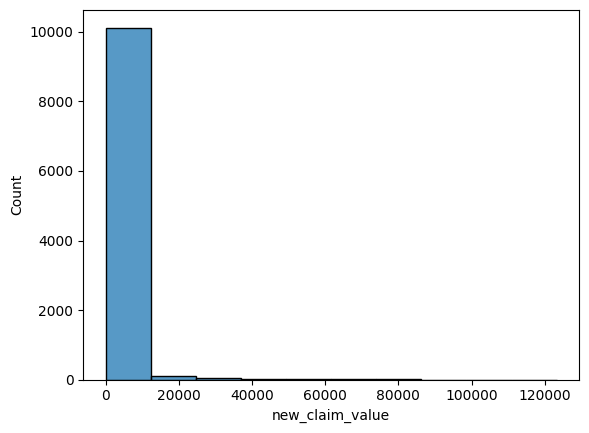

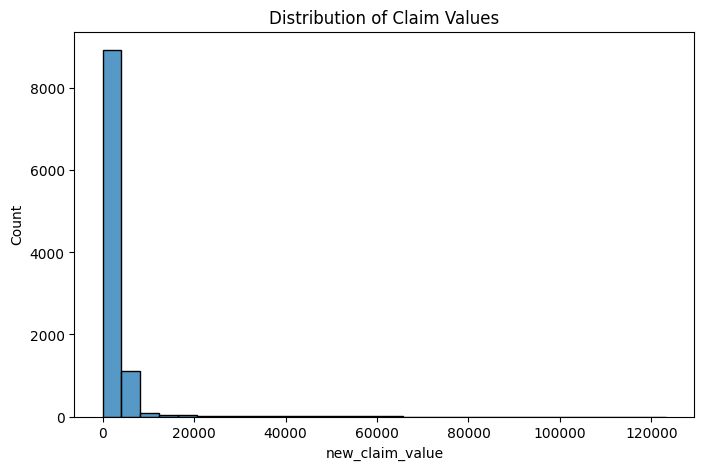

In [21]:
# Create hisogram for new claim value
sns.histplot(data_df['new_claim_value'], bins=10)





plt.figure(figsize=(8,5))
sns.histplot(data_df['new_claim_value'], bins=30)
plt.title('Distribution of Claim Values')
plt.show()

In [179]:
# Define bins
bins = [0.0, 5000, 10_000, 15_000, 20_000, 25_000, 30_000, 35_000, 40_000, 45_000, 50_000, np.inf]
# Define bin labels
labels = np.arange(1, 12)

# Apply the bins using cut
data_df['claim_value_cat'] = pd.cut(data_df['new_claim_value'], bins = bins, labels= labels, include_lowest=True)

<Axes: ylabel='claim_value_cat'>

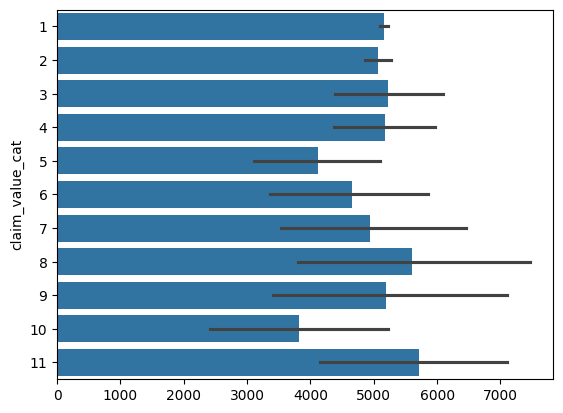

In [181]:

sns.barplot(data_df['claim_value_cat'])

In [183]:
# Create clean copy of training data
X = data_df.copy()
y = data_df['is_claim']

# Drop the target feature
X.drop(columns=['new_claim_value','is_claim'], inplace=True)

# Create train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=X['claim_value_cat'])

In [38]:
train_ratio = round((y_train.sum()/len(y_train))*100,2)
test_ratio = round((y_test.sum()/len(y_test)*100),2)

print(f'Train positive class ratio: {train_ratio}%')
print(f'Test positive class ratio: {test_ratio}%')

NameError: name 'y_train' is not defined

In [186]:
for set_ in (X_train, X_test):
    set_.drop(columns=['claim_value_cat'], inplace=True)